# Data check of the cleaned dataset (v8, read-only)

This notebook checks the cleaned dataset and **changes nothing** in it.

It checks:

1. Corrupt images and broken label files.
2. Exact duplicate images (same file content).
3. Leakage between train, valid and test (exact copies, near-duplicates, and copies made from the same original image).
4. Background images (no fire, no smoke).
5. Small targets (COCO definition: box area < 32 × 32 pixels).
6. Rotated or mirrored copies across the splits (Step 9).

**Result of Step 9:** one test image has a 180°-rotated copy in the training split. This case is reported as a limitation in the Methodology.

In [ ]:
# ======================= SETTINGS =======================
DATASET_DRIVE_LINK = "https://drive.google.com/file/d/1nBbOcdJcH4HDuX8eBl1lyeXgw09k_jwI/view?usp=sharing"
ZIP_PATH     = "/content/dataset_final_v8.zip"
EXTRACT_DIR  = "/content/dataset_final_v8"
OUT_DIR      = "/content/data_check"
EXPECTED_MD5 = "e4f0e4fc1bbe96ce7ac61d91151edf21"   # None for a new dataset version (the MD5 is then only printed)

NEAR_DUP_MAX_DIST = 5      # dHash distance (0-64) at or below which two images are flagged as near-duplicates
SMALL_AREA_PX     = 32 * 32  # COCO "small" object
MEDIUM_AREA_PX    = 96 * 96  # COCO "medium" object
SAMPLE_SIZE       = 300      # test images for the manual categorization
SAMPLE_SEED       = 0        # fixed, so the same 300 images are selected every time

## Step 1 - Get the dataset (download, verify MD5, extract)

In [ ]:
import os, sys, json, csv, time, shutil, hashlib, zipfile, random, subprocess, collections
from pathlib import Path
import numpy as np
from PIL import Image, ImageOps, ImageDraw

def md5_file(p, chunk=1 << 20):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

ROOT = Path(EXTRACT_DIR)
if (ROOT / ".extract_complete").exists() or (ROOT / "train").is_dir():
    print("Dataset already extracted:", ROOT)
else:
    zp = Path(ZIP_PATH)
    if not zp.exists():
        try:
            import gdown
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=False)
            import gdown
        gdown.download(url=DATASET_DRIVE_LINK, output=str(zp), quiet=False, fuzzy=True)
    got = md5_file(zp)
    print(f"Zip size: {zp.stat().st_size} bytes")
    if EXPECTED_MD5:
        print("MD5:", got, "OK" if got == EXPECTED_MD5 else f"-> MISMATCH (expected {EXPECTED_MD5})")
        if got != EXPECTED_MD5:
            raise RuntimeError("The zip does not match EXPECTED_MD5. Delete it and run again.")
    else:
        print("MD5:", got, "(EXPECTED_MD5 is None: write this value down, it identifies this dataset version)")
    with zipfile.ZipFile(zp) as z:
        z.extractall(ROOT)
    (ROOT / ".extract_complete").write_text("ok")
    print("Extracted to", ROOT)

yamls = sorted(ROOT.rglob("data.yaml"), key=lambda p: len(p.parts))
DS = yamls[0].parent if yamls else ROOT
SPLITS = {}
for key, names in {"train": ["train"], "valid": ["valid", "val", "validation"], "test": ["test"]}.items():
    for n in names:
        if (DS / n / "images").is_dir():
            SPLITS[key] = DS / n
            break
print("Dataset root:", DS, "| splits:", {k: str(v) for k, v in SPLITS.items()})
OUT = Path(OUT_DIR); OUT.mkdir(parents=True, exist_ok=True)
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

Downloading...
From (original): https://drive.google.com/uc?id=1nBbOcdJcH4HDuX8eBl1lyeXgw09k_jwI
From (redirected): https://drive.google.com/uc?id=1nBbOcdJcH4HDuX8eBl1lyeXgw09k_jwI&confirm=t&uuid=42fb311b-016e-46f0-9291-a77b3a153fe2
To: /content/dataset_final_v8.zip
100%|██████████| 414M/414M [00:06<00:00, 64.5MB/s]


Zip size: 414447684 bytes
MD5: e4f0e4fc1bbe96ce7ac61d91151edf21 OK
Extracted to /content/dataset_final_v8
Dataset root: /content/dataset_final_v8/dataset_final_v8/dataset | splits: {'train': '/content/dataset_final_v8/dataset_final_v8/dataset/train', 'valid': '/content/dataset_final_v8/dataset_final_v8/dataset/valid', 'test': '/content/dataset_final_v8/dataset_final_v8/dataset/test'}


## Step 2 - Corrupt images and label files

In [ ]:
RECORDS = []          # one row per image
PROBLEMS = []         # corrupt images and label problems
for split, d in SPLITS.items():
    imgs = sorted(p for p in (d / "images").iterdir() if p.suffix.lower() in IMG_EXT)
    label_dir = d / "labels"
    label_stems = {p.stem for p in label_dir.glob("*.txt")} if label_dir.is_dir() else set()
    for p in imgs:
        rec = {"split": split, "file": p.name, "path": str(p), "w": None, "h": None, "ok": True, "boxes": []}
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                im.load()
                rec["w"], rec["h"] = im.size
        except Exception as e:
            rec["ok"] = False
            PROBLEMS.append({"split": split, "file": p.name, "problem": "corrupt image", "detail": f"{type(e).__name__}: {e}"})
        lf = label_dir / (p.stem + ".txt")
        if not lf.exists():
            PROBLEMS.append({"split": split, "file": p.name, "problem": "missing label file", "detail": ""})
        else:
            for i, line in enumerate(lf.read_text().splitlines(), 1):
                parts = line.split()
                if not parts:
                    continue
                if len(parts) != 5:
                    PROBLEMS.append({"split": split, "file": p.name, "problem": "label line is not 5 values", "detail": f"line {i}: {line[:60]}"})
                    continue
                try:
                    c = int(float(parts[0])); cx, cy, bw, bh = map(float, parts[1:])
                except ValueError:
                    PROBLEMS.append({"split": split, "file": p.name, "problem": "label not numeric", "detail": f"line {i}: {line[:60]}"})
                    continue
                if c not in (0, 1):
                    PROBLEMS.append({"split": split, "file": p.name, "problem": "unknown class id", "detail": f"line {i}: class {c}"})
                    continue
                if not (0 <= cx <= 1 and 0 <= cy <= 1 and 0 < bw <= 1 and 0 < bh <= 1):
                    PROBLEMS.append({"split": split, "file": p.name, "problem": "box outside image or zero size", "detail": f"line {i}: {line[:60]}"})
                    continue
                rec["boxes"].append((c, cx, cy, bw, bh))   # only valid boxes are counted in the statistics
        RECORDS.append(rec)
    img_stems = {p.stem for p in imgs}
    for s in sorted(label_stems - img_stems):
        PROBLEMS.append({"split": split, "file": s + ".txt", "problem": "label file without image", "detail": ""})

print("Images checked:", len(RECORDS))
for split in SPLITS:
    n = sum(r["split"] == split for r in RECORDS)
    print(f"  {split:<6} {n:>6} images")
cnt = collections.Counter(p["problem"] for p in PROBLEMS)
print("Problems found:", dict(cnt) if cnt else "none")

Images checked: 8658
  train    7115 images
  valid     761 images
  test      782 images
Problems found: none


## Step 3 - Exact duplicates (identical file content)

In [ ]:
for r in RECORDS:
    r["md5"] = md5_file(r["path"])
by_md5 = collections.defaultdict(list)
for r in RECORDS:
    by_md5[r["md5"]].append(r)
EXACT_GROUPS = [g for g in by_md5.values() if len(g) > 1]
EXACT_CROSS = [g for g in EXACT_GROUPS if len({r["split"] for r in g}) > 1]
print("Groups of identical images:", len(EXACT_GROUPS), "| of them across different splits (leakage):", len(EXACT_CROSS))
for g in EXACT_CROSS[:10]:
    print("  ", [f'{r["split"]}/{r["file"]}' for r in g])

Groups of identical images: 0 | of them across different splits (leakage): 0


## Step 4 - Copies made from the same original image (Roboflow file names)

Roboflow names every exported file `<original name>.rf.<random id>.jpg`. Two files with the same original name come from the same source image (for example an augmented copy). If they are in different splits, this is leakage.

In [ ]:
def source_name(fname):
    return fname.split(".rf.")[0] if ".rf." in fname else Path(fname).stem
by_src = collections.defaultdict(list)
for r in RECORDS:
    r["source"] = source_name(r["file"])
    by_src[r["source"]].append(r)
SRC_GROUPS = {s: g for s, g in by_src.items() if len(g) > 1}
SRC_CROSS = {s: g for s, g in SRC_GROUPS.items() if len({r["split"] for r in g}) > 1}
n_rf = sum(".rf." in r["file"] for r in RECORDS)
print(f"Files with a Roboflow name: {n_rf} of {len(RECORDS)}")
print("Original images used more than once:", len(SRC_GROUPS), "| of them across different splits (leakage):", len(SRC_CROSS))
for s, g in list(SRC_CROSS.items())[:10]:
    print("  ", s, "->", sorted(collections.Counter(r["split"] for r in g).items()))

Files with a Roboflow name: 8658 of 8658
Original images used more than once: 689 | of them across different splits (leakage): 54
   test__94_jpg -> [('test', 1), ('train', 1)]
   train__0111_jpg -> [('train', 1), ('valid', 1)]
   train__103_jpg -> [('test', 1), ('train', 2)]
   train__109_jpg -> [('train', 1), ('valid', 1)]
   train__120_jpg -> [('train', 1), ('valid', 1)]
   train__1320_jpg -> [('test', 1), ('train', 2)]
   train__1494_jpg -> [('train', 2), ('valid', 1)]
   train__1541_jpg -> [('test', 1), ('train', 1)]
   train__200_jpg -> [('train', 3), ('valid', 1)]
   train__201_jpg -> [('test', 1), ('train', 1)]


## Step 5 - Near-duplicates across splits (perceptual hash)

Each image gets a 64-bit "difference hash" (dHash): very similar images get very similar hashes, even after resizing, compression or small colour changes. Every valid and test image is compared with every train image (and test with valid), also in its mirrored form. Pairs at distance <= `NEAR_DUP_MAX_DIST` are flagged and shown below so a person can confirm them.

Hashed 8658 images in 52 s
test vs train: 1427 near-duplicate pairs, 96 distinct test images
valid vs train: 150 near-duplicate pairs, 43 distinct valid images
test vs valid: 52 near-duplicate pairs, 40 distinct test images


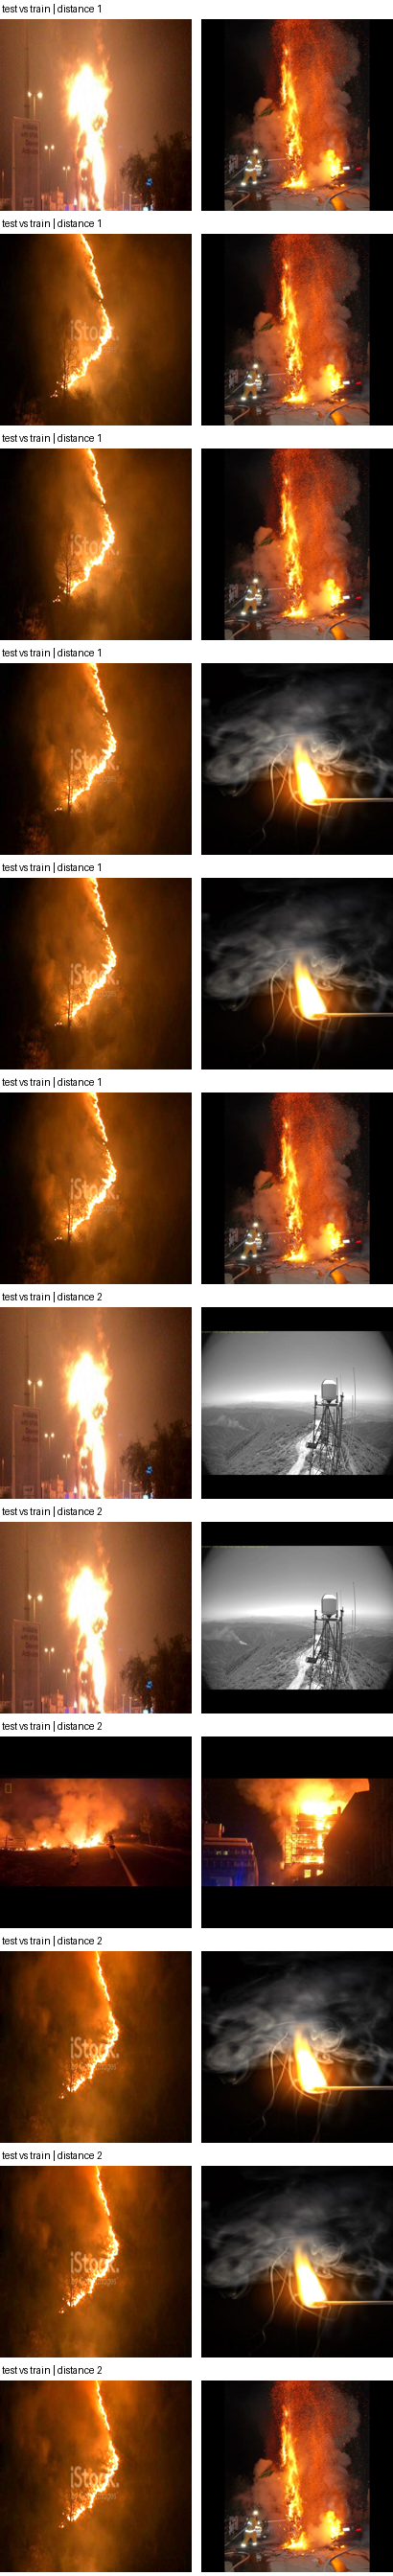

In [ ]:
def dhash(img, size=8):
    g = img.convert("L").resize((size + 1, size), Image.BILINEAR)
    a = np.asarray(g, dtype=np.int16)
    return np.packbits((a[:, 1:] > a[:, :-1]).flatten()).view(">u8")[0].astype(np.uint64)

_POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
def popcount(x):
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x)
    return _POP[x.view(np.uint8)].reshape(*x.shape, 8).sum(-1)

t0 = time.perf_counter()
for r in RECORDS:
    r["dhash"] = r["dhash_flip"] = None
    if not r["ok"]:
        continue
    with Image.open(r["path"]) as im:
        r["dhash"] = dhash(im)
        r["dhash_flip"] = dhash(ImageOps.mirror(im))
print(f"Hashed {len(RECORDS)} images in {time.perf_counter() - t0:.0f} s")

def cross_pairs(query_split, ref_split, max_dist=NEAR_DUP_MAX_DIST, chunk=256):
    Q = [r for r in RECORDS if r["split"] == query_split and r["dhash"] is not None]
    R = [r for r in RECORDS if r["split"] == ref_split and r["dhash"] is not None]
    if not Q or not R:
        return []
    rh = np.array([r["dhash"] for r in R], dtype=np.uint64)
    out = []
    for i in range(0, len(Q), chunk):
        part = Q[i:i + chunk]
        qh = np.array([r["dhash"] for r in part], dtype=np.uint64)
        qf = np.array([r["dhash_flip"] for r in part], dtype=np.uint64)
        d = np.minimum(popcount(qh[:, None] ^ rh[None, :]), popcount(qf[:, None] ^ rh[None, :]))
        for a, b in zip(*np.nonzero(d <= max_dist)):
            out.append({"query_split": query_split, "query_file": part[a]["file"], "ref_split": ref_split,
                        "ref_file": R[b]["file"], "dhash_distance": int(d[a, b]),
                        "identical_file": part[a]["md5"] == R[b]["md5"],
                        "same_roboflow_source": part[a]["source"] == R[b]["source"],
                        "_q": part[a]["path"], "_r": R[b]["path"]})
    return out

NEAR = cross_pairs("test", "train") + cross_pairs("valid", "train") + cross_pairs("test", "valid")
NEAR.sort(key=lambda x: x["dhash_distance"])
for a, b in (("test", "train"), ("valid", "train"), ("test", "valid")):
    sub = [p for p in NEAR if p["query_split"] == a and p["ref_split"] == b]
    print(f"{a} vs {b}: {len(sub)} near-duplicate pairs, {len({p['query_file'] for p in sub})} distinct {a} images")

# visual check of the closest pairs
if NEAR:
    show = NEAR[:12]
    tw = 200
    sheet = Image.new("RGB", (2 * tw + 10, len(show) * (tw + 24)), "white")
    dr = ImageDraw.Draw(sheet)
    for k, p in enumerate(show):
        y = k * (tw + 24)
        for j, path in enumerate((p["_q"], p["_r"])):
            with Image.open(path) as im:
                sheet.paste(im.convert("RGB").resize((tw, tw)), (j * (tw + 10), y + 20))
        dr.text((2, y + 3), f'{p["query_split"]} vs {p["ref_split"]} | distance {p["dhash_distance"]}', fill="black")
    sheet.save(OUT / "near_duplicates_preview.jpg", quality=85)
    try:
        from IPython.display import display
        display(sheet)
    except Exception:
        pass

## Step 6 - Background images and small targets

In [ ]:
SIZE_ROWS = []
for split in SPLITS:
    recs = [r for r in RECORDS if r["split"] == split and r["ok"]]
    bg = sum(len(r["boxes"]) == 0 for r in recs)
    c = collections.Counter()
    imgs_small = 0
    for r in recs:
        has_small = False
        for cls, cx, cy, bw, bh in r["boxes"]:
            area = bw * r["w"] * bh * r["h"]
            size = "small" if area < SMALL_AREA_PX else ("medium" if area < MEDIUM_AREA_PX else "large")
            c[(cls, size)] += 1
            has_small |= size == "small"
        r["has_small"] = has_small
        imgs_small += has_small
    row = {"split": split, "images": len(recs), "background_images": bg, "images_with_small_target": imgs_small}
    for cls, cname in ((0, "fire"), (1, "smoke")):
        for size in ("small", "medium", "large"):
            row[f"{cname}_{size}"] = c[(cls, size)]
    SIZE_ROWS.append(row)
    print(f"{split:<6} images {row['images']:>5} | background {bg:>4} | images with a small target {imgs_small:>4} | "
          f"fire S/M/L {row['fire_small']}/{row['fire_medium']}/{row['fire_large']} | "
          f"smoke S/M/L {row['smoke_small']}/{row['smoke_medium']}/{row['smoke_large']}")

train  images  7115 | background    0 | images with a small target  302 | fire S/M/L 406/3374/5401 | smoke S/M/L 41/869/6596
valid  images   761 | background    0 | images with a small target  131 | fire S/M/L 34/415/578 | smoke S/M/L 104/156/660
test   images   782 | background    0 | images with a small target   38 | fire S/M/L 44/394/645 | smoke S/M/L 13/180/714


## Step 7 - Random sample of 300 test images (for the manual categorization)

The sample is fixed (`SAMPLE_SEED = 0`), so anyone who runs this notebook gets the same 300 images. The CSV has empty columns for the two annotators. `leak_flag` marks images that also appear (exactly or nearly) in train or valid.

In [ ]:
leaked_test = {p["query_file"] for p in NEAR if p["query_split"] == "test"}
leaked_test |= {r["file"] for g in EXACT_CROSS for r in g if r["split"] == "test"}
leaked_test |= {r["file"] for g in SRC_CROSS.values() for r in g if r["split"] == "test"}
test_recs = sorted((r for r in RECORDS if r["split"] == "test" and r["ok"]), key=lambda r: r["file"])
sample = random.Random(SAMPLE_SEED).sample(test_recs, min(SAMPLE_SIZE, len(test_recs)))
with open(OUT / "test_sample_300.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["file", "n_fire_boxes", "n_smoke_boxes", "has_small_target_auto", "leak_flag",
                "weak_smoke_A", "complex_background_A", "weak_smoke_B", "complex_background_B", "final_after_adjudication", "notes"])
    for r in sample:
        w.writerow([r["file"], sum(b[0] == 0 for b in r["boxes"]), sum(b[0] == 1 for b in r["boxes"]),
                    int(r["has_small"]), int(r["file"] in leaked_test), "", "", "", "", "", ""])
print(f"Sample: {len(sample)} test images | with a small target: {sum(r['has_small'] for r in sample)} | "
      f"leak-flagged: {sum(r['file'] in leaked_test for r in sample)}")

Sample: 300 test images | with a small target: 13 | leak-flagged: 47


## Step 8 - Save the results and print the summary

In [ ]:
def write_csv(name, rows, cols):
    with open(OUT / name, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=cols, extrasaction="ignore")
        w.writeheader(); w.writerows(rows)

write_csv("problems.csv", PROBLEMS, ["split", "file", "problem", "detail"])
write_csv("exact_duplicates.csv",
          [{"group": i, "split": r["split"], "file": r["file"], "md5": r["md5"]} for i, g in enumerate(EXACT_GROUPS) for r in g],
          ["group", "split", "file", "md5"])
write_csv("same_source_across_splits.csv",
          [{"source": s, "split": r["split"], "file": r["file"]} for s, g in SRC_CROSS.items() for r in g],
          ["source", "split", "file"])
write_csv("near_duplicates_across_splits.csv", NEAR,
          ["query_split", "query_file", "ref_split", "ref_file", "dhash_distance", "identical_file", "same_roboflow_source"])
write_csv("target_sizes.csv", SIZE_ROWS, list(SIZE_ROWS[0].keys()))

tt = [p for p in NEAR if p["query_split"] == "test" and p["ref_split"] == "train"]
vt = [p for p in NEAR if p["query_split"] == "valid" and p["ref_split"] == "train"]
tv = [p for p in NEAR if p["query_split"] == "test" and p["ref_split"] == "valid"]
S = ["=" * 80, "DATA CHECK SUMMARY - MyData_Fire (nothing was modified)", "=" * 80,
     "Images: " + ", ".join(f"{k} {sum(r['split'] == k for r in RECORDS)}" for k in SPLITS),
     f"Corrupt images: {sum(not r['ok'] for r in RECORDS)}",
     f"Label problems: {dict(collections.Counter(p['problem'] for p in PROBLEMS if p['problem'] != 'corrupt image')) or 'none'}",
     f"Exact duplicate groups: {len(EXACT_GROUPS)} (across splits: {len(EXACT_CROSS)})",
     f"Same Roboflow source across splits: {len(SRC_CROSS)} original images",
     f"Near-duplicates (dHash <= {NEAR_DUP_MAX_DIST}, incl. mirrored): "
     f"test-train {len({p['query_file'] for p in tt})} test images | valid-train {len({p['query_file'] for p in vt})} valid images | "
     f"test-valid {len({p['query_file'] for p in tv})} test images",
     f"Test images flagged as possible leakage (any check): {len(leaked_test)} of {sum(r['split'] == 'test' for r in RECORDS)}"]
for row in SIZE_ROWS:
    S.append(f"{row['split']}: background {row['background_images']} | images with small target {row['images_with_small_target']} | "
             f"fire S/M/L {row['fire_small']}/{row['fire_medium']}/{row['fire_large']} | smoke S/M/L {row['smoke_small']}/{row['smoke_medium']}/{row['smoke_large']}")
S += [f"300-image sample saved: test_sample_300.csv (seed {SAMPLE_SEED})", "=" * 80]
SUMMARY = "\n".join(S)
(OUT / "summary.txt").write_text(SUMMARY)
print(SUMMARY)

zip_path = shutil.make_archive("/content/data_check_results", "zip", OUT)
print("\nAll results:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    pass

DATA CHECK SUMMARY - MyData_Fire (nothing was modified)
Images: train 7115, valid 761, test 782
Corrupt images: 0
Label problems: none
Exact duplicate groups: 0 (across splits: 0)
Same Roboflow source across splits: 54 original images
Near-duplicates (dHash <= 5, incl. mirrored): test-train 96 test images | valid-train 43 valid images | test-valid 40 test images
Test images flagged as possible leakage (any check): 127 of 782
train: background 0 | images with small target 302 | fire S/M/L 406/3374/5401 | smoke S/M/L 41/869/6596
valid: background 0 | images with small target 131 | fire S/M/L 34/415/578 | smoke S/M/L 104/156/660
test: background 0 | images with small target 38 | fire S/M/L 44/394/645 | smoke S/M/L 13/180/714
300-image sample saved: test_sample_300.csv (seed 0)

All results: /content/data_check_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 9 - Stronger leakage check (rotations and mirror)

The simple hash in Step 5 flags many **different** night-fire pictures as near-duplicates (dark image, bright fire in the middle). This step compares every valid and test image with train (and test with valid) in all 8 orientations, using only the fine detail of the picture, so it finds rotated or mirrored copies but not merely similar scenes.

Look at the two sheets it shows: the first has example pairs for each score band (decide from it from which score the pairs are really the same picture); the second has images that share the same original file name in different splits.

Thumbnails: {'train': 7115, 'valid': 761, 'test': 782}
test vs train: images with a match at score >= 0.4: 344, 0.6: 233, 0.8: 38, 0.9: 6
valid vs train: images with a match at score >= 0.4: 396, 0.6: 145, 0.8: 37, 0.9: 3
test vs valid: images with a match at score >= 0.4: 307, 0.6: 159, 0.8: 31, 0.9: 3
Same original name in different splits (prefix removed): 72 names

Test images with a near-identical picture (score >= 0.8) in train or valid: 41 of 782
Saved: leak_check_pairs.csv, leak_check_same_name.csv, leak_check_by_score.jpg, leak_check_same_name.jpg in /content/data_check


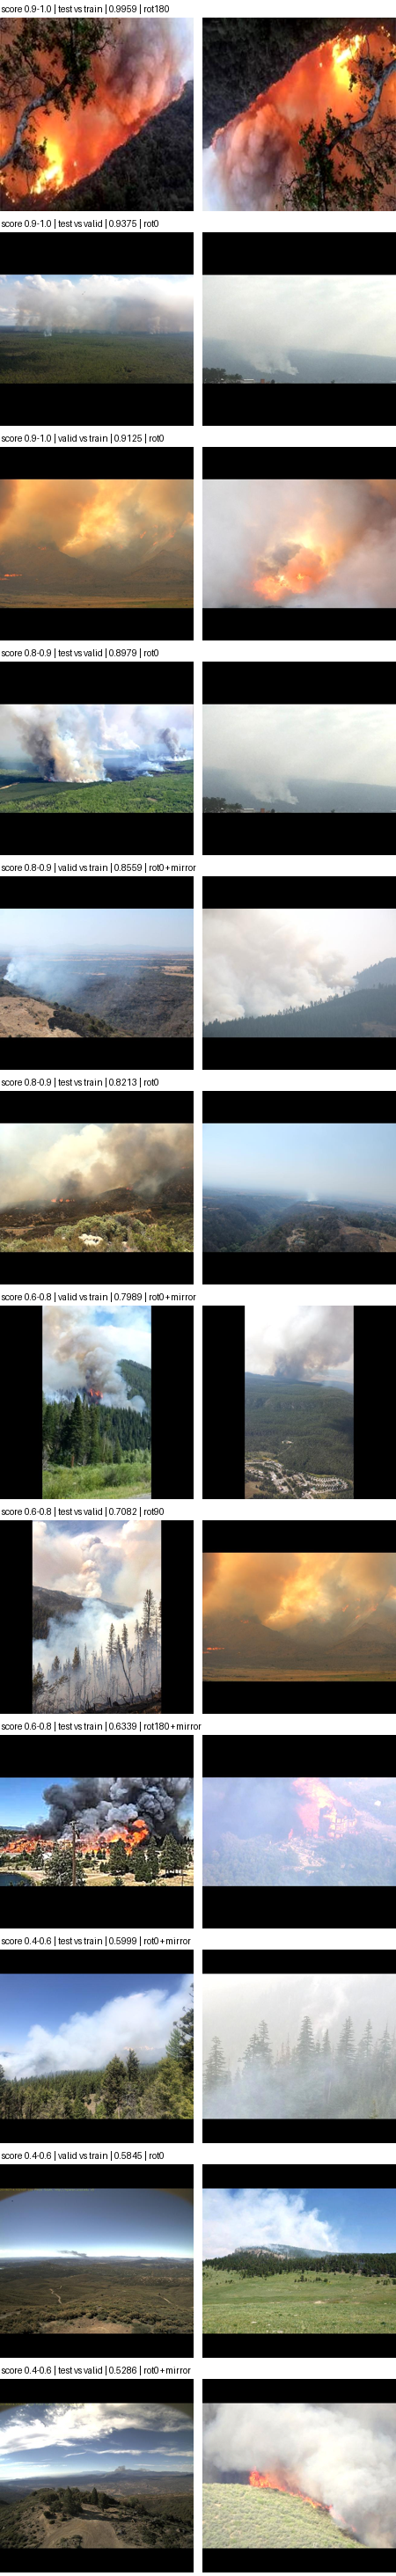

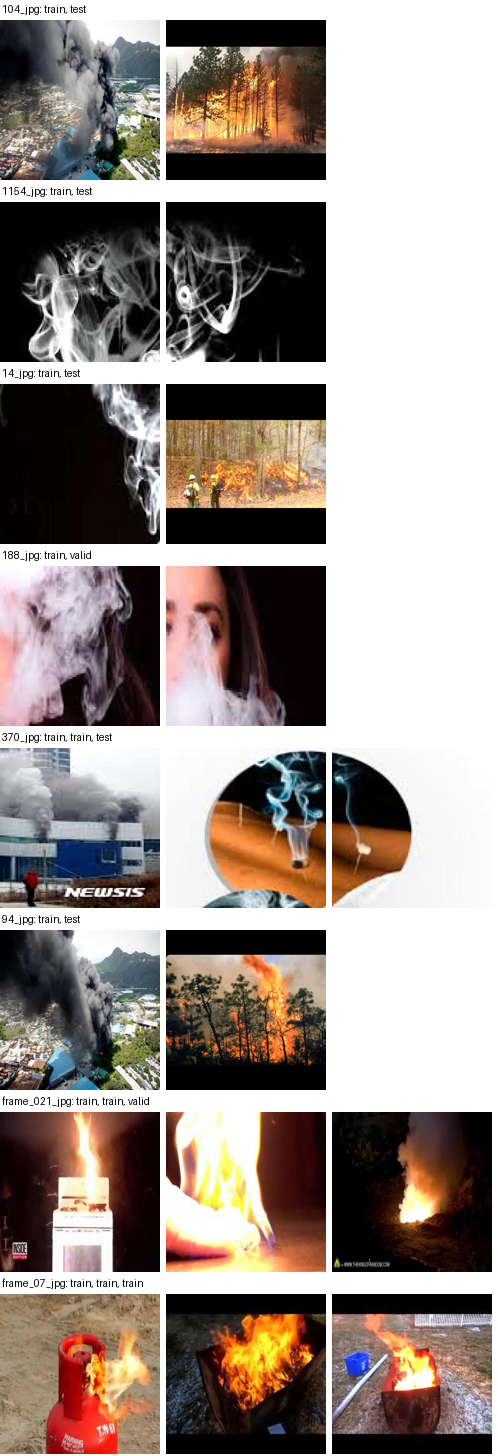

In [ ]:
# ===== Stronger leakage check: compares every valid/test image with train (and test with valid)
# in all 8 orientations (4 rotations x mirror). The score is the correlation of the FINE DETAIL of 64x64 grey
# thumbnails (thumbnail minus its blurred version), so two different dark scenes with a bright fire in the middle
# do not look alike (that is what fooled the simple hash).
# Read-only: nothing in the dataset is changed. Run it after the data-check notebook (same session).
import re, csv, collections, numpy as np
from PIL import Image, ImageDraw

THRESHOLDS = (0.4, 0.6, 0.8, 0.9)
LEAK_TH = 0.8           # pairs at or above this score are treated as the same picture (check the sheet below)

def thumb(path):
    with Image.open(path) as im:
        g = im.convert("L").resize((64, 64), Image.BOX)
    low = g.resize((16, 16), Image.BOX).resize((64, 64), Image.BILINEAR)
    return np.asarray(g, np.float32) - np.asarray(low, np.float32)

def unit(a):
    a = a.reshape(len(a), -1); a = a - a.mean(1, keepdims=True)
    return a / (np.linalg.norm(a, axis=1, keepdims=True) + 1e-6)

RECS = {s: [r for r in RECORDS if r["split"] == s and r["ok"]] for s in ("train", "valid", "test")}
TH_ = {s: np.stack([thumb(r["path"]) for r in RECS[s]]) for s in RECS}
print("Thumbnails:", {s: len(v) for s, v in TH_.items()})

def best_match(q, ref):
    R = unit(TH_[ref]).T
    best = np.full(len(TH_[q]), -2.0, np.float32); arg = np.zeros(len(TH_[q]), int); how = [""] * len(TH_[q])
    for k in range(4):
        for flip in (False, True):
            v = np.rot90(TH_[q], k, axes=(1, 2))
            if flip: v = v[:, :, ::-1]
            S = unit(np.ascontiguousarray(v)) @ R
            m, a = S.max(1), S.argmax(1)
            for i in np.nonzero(m > best)[0]:
                best[i], arg[i], how[i] = m[i], a[i], f"rot{90 * k}" + ("+mirror" if flip else "")
    return best, arg, how

PAIRS = []
for q, ref in (("test", "train"), ("valid", "train"), ("test", "valid")):
    best, arg, how = best_match(q, ref)
    counts = {t: int((best >= t).sum()) for t in THRESHOLDS}
    print(f"{q} vs {ref}: images with a match at score >= " + ", ".join(f"{t}: {n}" for t, n in counts.items()))
    for i in np.nonzero(best >= min(THRESHOLDS))[0]:
        PAIRS.append({"query_split": q, "query_file": RECS[q][i]["file"], "ref_split": ref, "ref_file": RECS[ref][arg[i]]["file"],
                      "score": round(float(best[i]), 4), "transform": how[i],
                      "_q": RECS[q][i]["path"], "_r": RECS[ref][arg[i]]["path"]})
PAIRS.sort(key=lambda p: -p["score"])

# same original image by name (the train__/valid__/test__ prefix added during cleaning is removed first)
base = lambda f: re.sub(r"^(train|valid|test)__", "", f.split(".rf.")[0])
groups = collections.defaultdict(list)
for r in RECORDS:
    groups[base(r["file"])].append(r)
NAME_CROSS = {b: g for b, g in groups.items() if len({r["split"] for r in g}) > 1}
print(f"Same original name in different splits (prefix removed): {len(NAME_CROSS)} names")

# visual calibration sheet: 3 pairs from each score band
bands = [(0.9, 1.01), (0.8, 0.9), (0.6, 0.8), (0.4, 0.6)]
show = []
for lo, hi in bands:
    sel = [p for p in PAIRS if lo <= p["score"] < hi]
    show += [(f"score {lo}-{min(hi, 1.0)}", p) for p in sel[:: max(1, len(sel) // 3)][:3]]
tw = 220
sheet = Image.new("RGB", (2 * tw + 10, max(1, len(show)) * (tw + 24)), "white"); dr = ImageDraw.Draw(sheet)
for k, (lab, p) in enumerate(show):
    y = k * (tw + 24)
    for j, path in enumerate((p["_q"], p["_r"])):
        with Image.open(path) as im:
            sheet.paste(im.convert("RGB").resize((tw, tw)), (j * (tw + 10), y + 20))
    dr.text((2, y + 4), f'{lab} | {p["query_split"]} vs {p["ref_split"]} | {p["score"]} | {p["transform"]}', fill="black")
sheet.save(OUT / "leak_check_by_score.jpg", quality=85)

# name groups sheet: first 8 groups, up to 3 images each
tw2 = 160; ng = list(NAME_CROSS.items())[:8]
sheet2 = Image.new("RGB", (3 * (tw2 + 6), max(1, len(ng)) * (tw2 + 22)), "white"); d2 = ImageDraw.Draw(sheet2)
for k, (b, g) in enumerate(ng):
    y = k * (tw2 + 22); d2.text((2, y + 3), f"{b}: " + ", ".join(r["split"] for r in g[:3]), fill="black")
    for j, r in enumerate(g[:3]):
        with Image.open(r["path"]) as im:
            sheet2.paste(im.convert("RGB").resize((tw2, tw2)), (j * (tw2 + 6), y + 20))
sheet2.save(OUT / "leak_check_same_name.jpg", quality=85)

with open(OUT / "leak_check_pairs.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=["query_split", "query_file", "ref_split", "ref_file", "score", "transform"], extrasaction="ignore")
    w.writeheader(); w.writerows(PAIRS)
with open(OUT / "leak_check_same_name.csv", "w", newline="") as f:
    w = csv.writer(f); w.writerow(["original_name", "split", "file"])
    for b, g in NAME_CROSS.items():
        for r in g: w.writerow([b, r["split"], r["file"]])

lt = {p["query_file"] for p in PAIRS if p["query_split"] == "test" and p["score"] >= LEAK_TH}
print(f"\nTest images with a near-identical picture (score >= {LEAK_TH}) in train or valid: {len(lt)} of {len(RECS['test'])}")
print("Saved: leak_check_pairs.csv, leak_check_same_name.csv, leak_check_by_score.jpg, leak_check_same_name.jpg in", OUT)
try:
    from IPython.display import display
    display(sheet); display(sheet2)
except Exception:
    pass
